# Amount và hành vi tài chính quanh nhãn

Notebook chứa mã phân tích theo đúng thứ tự từ các file nguồn trong `src/`. Chạy với kernel của `.venv` tại repo. Các bước có thể đọc toàn bộ raw và ghi vào `outputs/`; kiểm tra phạm vi và quy ước thời gian của từng phần trước khi diễn giải. Mã cũ dùng UTC hoặc mẫu là phương pháp cũ, chưa được coi là kết quả Moscow/toàn bộ khách hàng. Script nguồn vẫn được giữ để đối chiếu.

In [1]:
from pathlib import Path
import sys
import time
import pandas as pd
from IPython.display import display, Image, SVG, Markdown
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').exists())
sys.path.insert(0, str(ROOT / 'src'))
sys.path.insert(0, str(ROOT / 'src/scripts'))
sys.path.insert(0, str(ROOT / 'src/mbd_mini_eda_fixes'))
def show_generated_results(started_ns, source):
    changed = sorted((p for base in (ROOT / 'outputs', ROOT / 'docs') if base.exists() for p in base.rglob('*') if p.is_file() and p.stat().st_mtime_ns >= started_ns), key=lambda p: p.as_posix())
    display(Markdown(f'### Kết quả: `{source}`'))
    if not changed:
        display(Markdown('Không có file kết quả mới từ phần này.'))
        return
    images = [p for p in changed if p.suffix.lower() in ('.png', '.jpg', '.jpeg', '.svg')]
    png_stems = {p.with_suffix('') for p in images if p.suffix.lower() == '.png'}
    for p in images:
        if p.suffix.lower() == '.svg' and p.with_suffix('') in png_stems:
            continue
        display(Markdown(f'**{p.relative_to(ROOT).as_posix()}**'))
        display(SVG(filename=str(p)) if p.suffix.lower() == '.svg' else Image(filename=str(p)))
    tables = [p for p in changed if p.suffix.lower() == '.csv']
    for p in tables:
        display(Markdown(f'**{p.relative_to(ROOT).as_posix()}** — 5 dòng đầu'))
        try:
            display(pd.read_csv(p, nrows=5))
        except Exception as exc:
            display(Markdown(f'Không đọc được bảng: `{type(exc).__name__}: {exc}`'))
    others = [p.relative_to(ROOT).as_posix() for p in changed if p not in images and p not in tables]
    if others:
        display(Markdown('File kết quả khác: ' + ', '.join(f'`{p}`' for p in others)))

## Analyze Amount11 Target Quantiles

Nguồn: `src/scripts/analyze_amount11_target_quantiles.py`. Chạy các ô của phần này theo thứ tự.

In [2]:
__file__ = str(ROOT / 'src/scripts/analyze_amount11_target_quantiles.py')
sys.argv = [__file__]
__eda_started_ns = time.time_ns()
__name__ = '__main__'
__package__ = None


In [3]:
"""Past-only currency11 features vs labels; train-fixed quintiles and client bootstrap."""
from pathlib import Path
import json
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

ROOT = Path(__file__).resolve().parents[2]
SOURCE = ROOT / 'outputs/propensity_processing_v3'
OUT = ROOT / 'outputs/amount11_target_quantiles_20261116'
LABELS = ['y_any'] + [f'target_{i}' for i in range(1, 5)]
METRICS = [f'trx_{w}d_main_amount_{s}' for w in (30, 84)
           for s in ('sum', 'mean', 'median', 'max')]


def main():
    OUT.mkdir(exist_ok=True)
    assert json.loads((SOURCE / 'manifest.json').read_text())['status'] == 'ready'
    cols = ['client_id', 'cutoff', 'supervised_eligible'] + LABELS + METRICS
    frames = []
    for file in sorted((SOURCE / 'features').rglob('*.parquet')):
        # Month partition names are verified against the stored cutoff below.
        if any(f'month=2022-{m:02d}' in str(file) for m in range(2, 12)):
            frames.append(pq.read_table(file, columns=cols).to_pandas())
    d = pd.concat(frames, ignore_index=True)
    d['month'] = pd.to_datetime(d.cutoff).dt.strftime('%Y-%m')
    assert set(d.month) == {f'2022-{m:02d}' for m in range(2, 12)}
    assert not d.duplicated(['client_id', 'cutoff']).any()
    assert d.supervised_eligible.all() and d[LABELS].isin([0, 1]).all().all()
    assert np.array_equal(d.y_any, d[LABELS[1:]].max(axis=1))
    d['split'] = np.where(d.month < '2022-09', 'train', 'validation')
    rows, monthly, thresholds, effects = [], [], {}, []
    rng = np.random.default_rng(20261116)
    for metric in METRICS:
        values = d[metric]
        assert (values.dropna() > 0).all()
        edges = values[d.split.eq('train')].dropna().quantile([.2,.4,.6,.8]).to_numpy()
        assert len(np.unique(edges)) == 4
        thresholds[metric] = edges.tolist()
        group = pd.Series('no_currency11_amount', index=d.index)
        valid = values.notna()
        group.loc[valid] = ('Q' + (np.searchsorted(edges, values[valid], side='left') + 1).astype(str))
        z = d[['client_id','month','split'] + LABELS].copy()
        z['group'] = group
        z['amount_value'] = values
        for (split, g), a in z.groupby(['split','group'], observed=True):
            item = dict(metric=metric,split=split,group=g,n=len(a),clients=a.client_id.nunique(),
                        amount_min=a.amount_value.min(),amount_median=a.amount_value.median(),amount_max=a.amount_value.max())
            for label in LABELS:
                item[f'{label}_positive'] = int(a[label].sum())
                item[f'{label}_rate_pct'] = 100*a[label].mean()
            rows.append(item)
        for (month, g), a in z.groupby(['month','group'], observed=True):
            monthly.append(dict(metric=metric,month=month,group=g,n=len(a),positive=int(a.y_any.sum()),rate_pct=100*a.y_any.mean()))
        v = z[z.split.eq('validation') & z.group.isin(['Q1','Q5'])]
        # Resample whole clients, not customer-month rows; same weight for all months.
        agg = v.groupby(['client_id','group']).y_any.agg(['sum','size']).unstack(fill_value=0)
        p1,n1,p5,n5 = [agg[(s,g)].to_numpy(dtype=float) for s,g in [('sum','Q1'),('size','Q1'),('sum','Q5'),('size','Q5')]]
        diffs = []
        for _ in range(500):
            weights = rng.poisson(1, size=len(agg))
            diffs.append(100*((weights@p5)/(weights@n5)-(weights@p1)/(weights@n1)))
        effect = dict(metric=metric,validation_q1_rate_pct=100*p1.sum()/n1.sum(),
                      validation_q5_rate_pct=100*p5.sum()/n5.sum(),
                      q5_minus_q1_pp=100*(p5.sum()/n5.sum()-p1.sum()/n1.sum()),
                      lift_q5_over_q1=(p5.sum()/n5.sum())/(p1.sum()/n1.sum()),
                      ci95_low_pp=float(np.quantile(diffs,.025)),ci95_high_pp=float(np.quantile(diffs,.975)))
        effects.append(effect)
        print(json.dumps(effect),flush=True)
    rates = pd.DataFrame(rows)
    rates.to_csv(OUT / 'rates_by_quintile.csv',index=False)
    pd.DataFrame(monthly).to_csv(OUT / 'rates_by_month.csv',index=False)
    pd.DataFrame(effects).to_csv(OUT / 'validation_effects.csv',index=False)
    (OUT / 'thresholds.json').write_text(json.dumps(thresholds,indent=2))
    d.groupby(['split','month']).y_any.agg(['size','sum','mean']).to_csv(OUT / 'cohort_summary.csv')
    fig, axes = plt.subplots(1,2,figsize=(11,4.5))
    for ax, suffix, title in zip(axes,('sum','median'),('Total amount, previous 30 days','Median transaction amount, previous 30 days')):
        metric = f'trx_30d_main_amount_{suffix}'
        for split in ('train','validation'):
            a = rates[(rates.metric==metric)&(rates.split==split)&rates.group.str.startswith('Q')].sort_values('group')
            ax.plot(a.group,a.y_any_rate_pct,marker='o',label=split)
        ax.set(title=title,xlabel='Quintile (train-fixed thresholds)',ylabel='Any-purchase rate (%)')
        ax.grid(alpha=.2)
        ax.legend()
    fig.tight_layout()
    fig.savefig(OUT / 'amount11_purchase_rates.png',dpi=170)
    plt.close(fig)
    (OUT / 'methodology.json').write_text(json.dumps(dict(status='ready',rows=len(d),
        source=str(SOURCE),unit='customer-month, not transaction',currency=11,
        labels=LABELS,windows_days=[30,84],train='2022-02 through 2022-08',validation='2022-09 through 2022-11',
        reserved_months_excluded=['2022-12','2023-01'],
        grouping='quintiles from nonmissing train customer-month feature values; ties kept together; frozen in validation; missing separate',
        uncertainty='500 Poisson cluster-bootstrap draws by client; percentile 95% CI of pooled validation Q5-Q1 rate difference; unadjusted exploratory comparisons',
        limitations='Association, not causation. Multiple exploratory metrics; CI not multiplicity adjusted. No control for activity, prior purchase, source availability or other confounding. Monthly tables show stability.',
        raw_modified=False),indent=2),encoding='utf-8')


if __name__ == '__main__':
    main()

{"metric": "trx_30d_main_amount_sum", "validation_q1_rate_pct": 0.5758506885171276, "validation_q5_rate_pct": 1.8212699776945587, "q5_minus_q1_pp": 1.245419289177431, "lift_q5_over_q1": 3.1627468960478433, "ci95_low_pp": 1.10494425268288, "ci95_high_pp": 1.394358317028576}


{"metric": "trx_30d_main_amount_mean", "validation_q1_rate_pct": 0.7149036929101589, "validation_q5_rate_pct": 1.2438686176707991, "q5_minus_q1_pp": 0.5289649247606402, "lift_q5_over_q1": 1.7399107460298355, "ci95_low_pp": 0.4082661313109773, "ci95_high_pp": 0.6501799826075838}


{"metric": "trx_30d_main_amount_median", "validation_q1_rate_pct": 1.0383002131609709, "validation_q5_rate_pct": 0.7509412342445572, "q5_minus_q1_pp": -0.28735897891641377, "lift_q5_over_q1": 0.7232409516303705, "ci95_low_pp": -0.40594649481578704, "ci95_high_pp": -0.17530860825705094}


{"metric": "trx_30d_main_amount_max", "validation_q1_rate_pct": 0.6044570151228302, "validation_q5_rate_pct": 1.6445733222866612, "q5_minus_q1_pp": 1.0401163071638309, "lift_q5_over_q1": 2.720744868768661, "ci95_low_pp": 0.9142124074243624, "ci95_high_pp": 1.204597581016909}


{"metric": "trx_84d_main_amount_sum", "validation_q1_rate_pct": 0.5035603288878399, "validation_q5_rate_pct": 1.7847588473591685, "q5_minus_q1_pp": 1.2811985184713286, "lift_q5_over_q1": 3.5442800891423984, "ci95_low_pp": 1.1399078688928017, "ci95_high_pp": 1.4101655433171405}


{"metric": "trx_84d_main_amount_mean", "validation_q1_rate_pct": 0.6331375039695142, "validation_q5_rate_pct": 1.1788796815493847, "q5_minus_q1_pp": 0.5457421775798705, "lift_q5_over_q1": 1.8619646982816362, "ci95_low_pp": 0.423904422688223, "ci95_high_pp": 0.6504267206462276}


{"metric": "trx_84d_main_amount_median", "validation_q1_rate_pct": 0.9131869016010942, "validation_q5_rate_pct": 0.6846773295728652, "q5_minus_q1_pp": -0.22850957202822886, "lift_q5_over_q1": 0.7497669188776338, "ci95_low_pp": -0.3332534727161329, "ci95_high_pp": -0.1240762630240464}


{"metric": "trx_84d_main_amount_max", "validation_q1_rate_pct": 0.527798018788034, "validation_q5_rate_pct": 1.5573484348939142, "q5_minus_q1_pp": 1.0295504161058802, "lift_q5_over_q1": 2.950652293977921, "ci95_low_pp": 0.885722798279483, "ci95_high_pp": 1.1569935373776488}


### Kết quả: `src/scripts/analyze_amount11_target_quantiles.py`

**outputs/amount11_target_quantiles_20261116/amount11_purchase_rates.png**

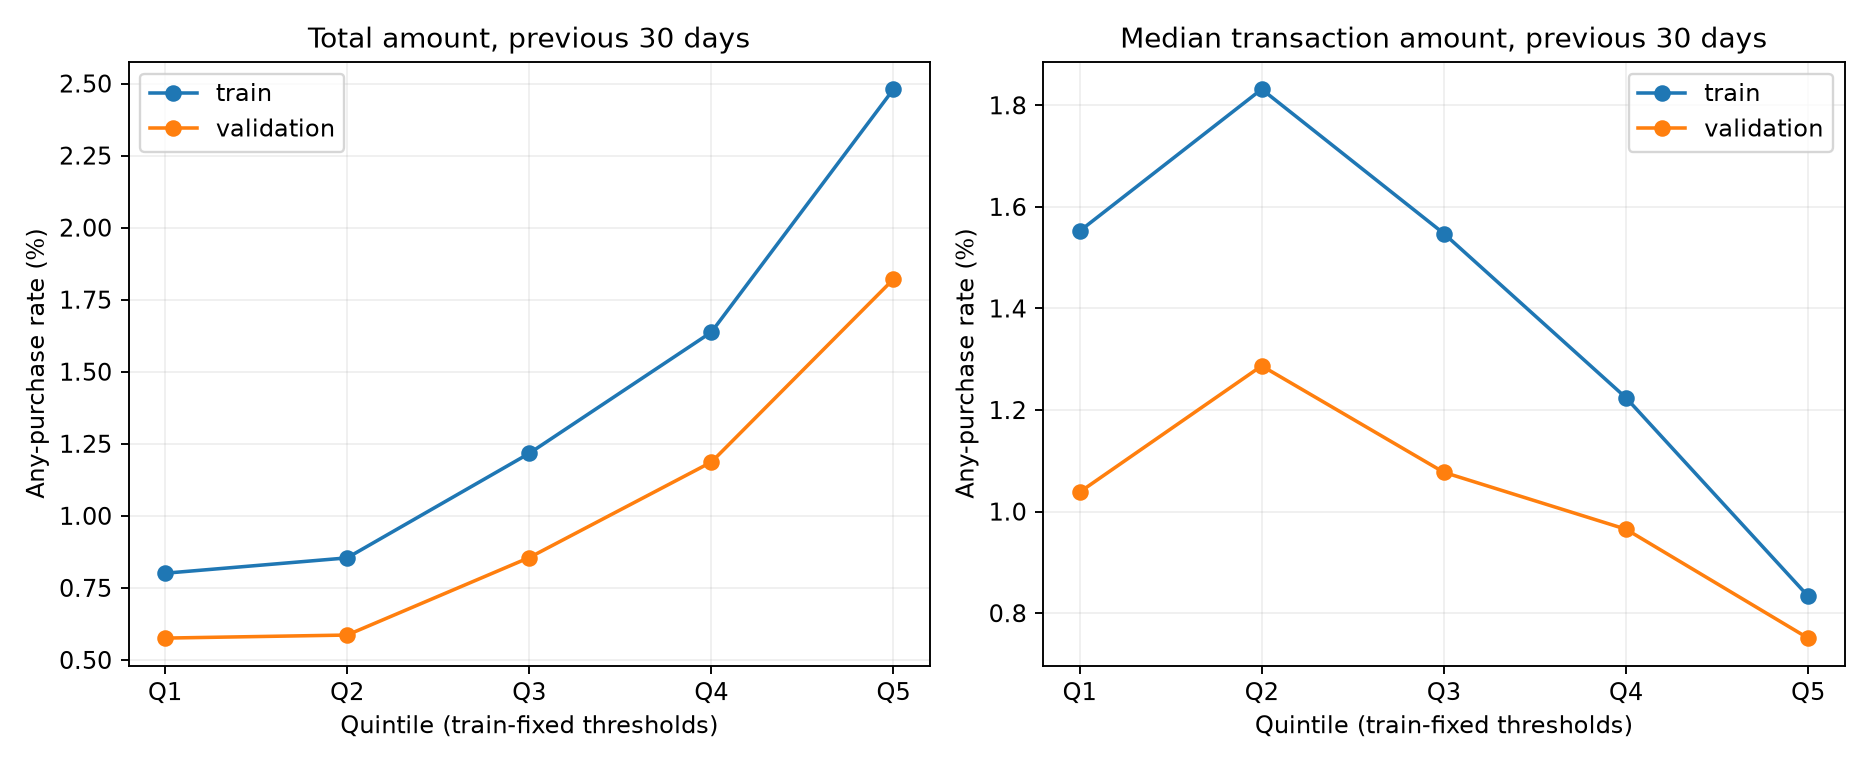

**outputs/amount11_target_quantiles_20261116/cohort_summary.csv** — 5 dòng đầu

,split,month,size,sum,mean
0,train,2022-02,100224,1041,0.010387
1,train,2022-03,100224,1567,0.015635
2,train,2022-04,100224,1698,0.016942
3,train,2022-05,100224,1100,0.010975
4,train,2022-06,100224,1177,0.011744


**outputs/amount11_target_quantiles_20261116/rates_by_month.csv** — 5 dòng đầu

,metric,month,group,n,positive,rate_pct
0,trx_30d_main_amount_sum,2022-02,Q1,15610,126,0.807175
1,trx_30d_main_amount_sum,2022-02,Q2,15608,113,0.723988
2,trx_30d_main_amount_sum,2022-02,Q3,15294,161,1.052700
3,trx_30d_main_amount_sum,2022-02,Q4,14874,196,1.317736
4,trx_30d_main_amount_sum,2022-02,Q5,13609,302,2.219120


**outputs/amount11_target_quantiles_20261116/rates_by_quintile.csv** — 5 dòng đầu

,metric,split,group,n,clients,amount_min,amount_median,amount_max,y_any_positive,y_any_rate_pct,target_1_positive,target_1_rate_pct,target_2_positive,target_2_rate_pct,target_3_positive,target_3_rate_pct,target_4_positive,target_4_rate_pct
0,trx_30d_main_amount_sum,train,Q1,107005,40733,4.846005e-04,1.918279e+04,8.468518e+04,857,0.800897,440,0.411196,12,0.011214,266,0.248587,174,0.162609
1,trx_30d_main_amount_sum,train,Q2,107004,44105,8.468527e+04,2.171489e+05,4.519027e+05,914,0.854174,377,0.352323,26,0.024298,339,0.316811,231,0.215880
2,trx_30d_main_amount_sum,train,Q3,107005,44048,4.519028e+05,8.564870e+05,1.539111e+06,1302,1.216766,528,0.493435,41,0.038316,513,0.479417,291,0.271950
3,trx_30d_main_amount_sum,train,Q4,107004,40289,1.539171e+06,2.751890e+06,5.156278e+06,1752,1.637322,681,0.636425,68,0.063549,680,0.635490,421,0.393443
4,trx_30d_main_amount_sum,train,Q5,107005,29210,5.156293e+06,1.169552e+07,2.131694e+11,2654,2.480258,993,0.927994,176,0.164478,1119,1.045746,529,0.494369


**outputs/amount11_target_quantiles_20261116/validation_effects.csv** — 5 dòng đầu

,metric,validation_q1_rate_pct,validation_q5_rate_pct,q5_minus_q1_pp,lift_q5_over_q1,ci95_low_pp,ci95_high_pp
0,trx_30d_main_amount_sum,0.575851,1.821270,1.245419,3.162747,1.104944,1.394358
1,trx_30d_main_amount_mean,0.714904,1.243869,0.528965,1.739911,0.408266,0.650180
2,trx_30d_main_amount_median,1.038300,0.750941,-0.287359,0.723241,-0.405946,-0.175309
3,trx_30d_main_amount_max,0.604457,1.644573,1.040116,2.720745,0.914212,1.204598
4,trx_84d_main_amount_sum,0.503560,1.784759,1.281199,3.544280,1.139908,1.410166


File kết quả khác: `outputs/amount11_target_quantiles_20261116/methodology.json`, `outputs/amount11_target_quantiles_20261116/thresholds.json`

In [4]:
show_generated_results(__eda_started_ns, 'src/scripts/analyze_amount11_target_quantiles.py')

## Analyze Purchase Event Financial Eda

Nguồn: `src/scripts/analyze_purchase_event_financial_eda.py`. Chạy các ô của phần này theo thứ tự.

In [5]:
__file__ = str(ROOT / 'src/scripts/analyze_purchase_event_financial_eda.py')
sys.argv = [__file__]
__eda_started_ns = time.time_ns()
__name__ = '__main__'
__package__ = None


In [6]:
"""Retrospective financial-activity EDA around first observed any-product month.

HISTORICAL METHOD: sampled reference and restricted anchor months; superseded by
analyze_full_population_temporal_eda.py under the full-population rules of 18 Nov.

No prediction cutoff, model, separated product analysis, or causal inference.
Raw naive timestamps assumed UTC; calendar grouping Europe/Moscow.
"""
from pathlib import Path
import json
import hashlib
import numpy as np
import pandas as pd
import duckdb
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

ROOT=Path(__file__).resolve().parents[2]
OUT=ROOT/'outputs/purchase_event_financial_eda_20261118'
OUT.mkdir(parents=True,exist_ok=True)
plt.rcParams.update({'font.family':'DejaVu Sans','figure.dpi':130,'axes.spines.top':False,'axes.spines.right':False})
METRICS=['trx_events','amount11','trx_types','geo_events','geo_cells','dialog_events']


def figsave(fig,name,note):
    fig.text(.01,.012,note,fontsize=8,color='#475569')
    fig.tight_layout(rect=(0,.055,1,.96))
    for ext in ['png','svg']:fig.savefig(OUT/f'{name}.{ext}',bbox_inches='tight')
    plt.close(fig)


def wmean(v,w):
    v=np.asarray(v);w=np.asarray(w);ok=np.isfinite(v)&np.isfinite(w)&(w>0)
    return np.average(v[ok],weights=w[ok]) if ok.any() else np.nan


def wmedian(v,w):
    v=np.asarray(v);w=np.asarray(w);ok=np.isfinite(v)&np.isfinite(w)&(w>0)
    v=v[ok];w=w[ok]
    if not len(v):return np.nan
    order=np.argsort(v);v=v[order];w=w[order]
    return v[np.searchsorted(np.cumsum(w),w.sum()/2)]


def extract():
    c=duckdb.connect();c.execute("SET memory_limit='3GB'");c.execute('SET threads=2');c.execute('SET preserve_insertion_order=false')
    c.execute(f"SET temp_directory='{OUT.as_posix()}/tmp'")
    labels=c.execute(f"SELECT client_id,date_trunc('month',cast(mon AS DATE))::DATE AS month,greatest(target_1,target_2,target_3,target_4) y FROM read_parquet('{ROOT.as_posix()}/data/MBD-mini/targets/**/*.parquet')").df()
    assert not labels.duplicated(['client_id','month']).any()
    assert labels.y.isin([0,1]).all()
    labels.to_parquet(OUT/'labels_any.parquet',index=False)
    clients=c.execute(f"SELECT client_id FROM read_parquet('{ROOT.as_posix()}/data/MBD-mini/client_split/**/*.parquet')").df()
    assert clients.client_id.is_unique
    monthly=clients.merge(pd.DataFrame({'month':pd.date_range('2021-01-01','2022-12-01',freq='MS')}),how='cross')
    sql={
      'trx':"count(*) trx_events,count(distinct event_type) trx_types,coalesce(sum(amount) FILTER(WHERE currency=11),0) amount11,count(*) FILTER(WHERE currency=11) amount11_events",
      'geo':"count(*) geo_events,count(distinct geohash_4) geo_cells",
      'dialog':"count(*) dialog_events"
    }
    for source,expr in sql.items():
        print('Aggregate raw monthly:',source,flush=True)
        a=c.execute(f"SELECT client_id,date_trunc('month',event_time+INTERVAL '3 hours') AS month,{expr} FROM read_parquet('{ROOT.as_posix()}/data/MBD-mini/detail/{source}/**/*.parquet') GROUP BY 1,2").df()
        a.to_parquet(OUT/f'{source}_monthly.parquet',index=False)
        monthly=monthly.merge(a,on=['client_id','month'],how='left',validate='one_to_one')
    numeric=[x for x in monthly if x not in ['client_id','month']]
    monthly[numeric]=monthly[numeric].fillna(0)
    # Values before source-wide coverage are unavailable, not inactive.
    monthly.loc[monthly.month<'2022-01-01',['geo_events','geo_cells']]=np.nan
    monthly.loc[monthly.month<'2021-03-01','dialog_events']=np.nan
    monthly.to_parquet(OUT/'monthly_panel.parquet',index=False)
    types=c.execute(f"SELECT client_id,date_trunc('month',event_time+INTERVAL '3 hours') AS month,event_type,coalesce(sum(amount) FILTER(WHERE currency=11),0) amount11,count(*) events FROM read_parquet('{ROOT.as_posix()}/data/MBD-mini/detail/trx/**/*.parquet') GROUP BY 1,2,3").df()
    types.to_parquet(OUT/'trx_type_monthly.parquet',index=False)
    return monthly,labels,types

In [7]:
def analyze(monthly,labels,types):
    first=labels[labels.y.eq(1)].groupby('client_id').month.min().rename('anchor')
    cases=first[first.between('2022-04-01','2022-09-01')].reset_index()
    never=set(labels.client_id)-set(first.index)
    # Fixed reproducible reference sample; all qualifying first-observed buyers retained.
    reference_ids=pd.Series(sorted(never)).sample(n=min(20000,len(never)),random_state=20261118).sort_values().tolist()
    pd.DataFrame({'client_id':reference_ids}).to_csv(OUT/'reference_customer_ids.csv',index=False)
    case_ids=set(cases.client_id)
    anchors=[]
    for month in sorted(cases.anchor.unique()):
        buyers=cases[cases.anchor.eq(month)][['client_id','anchor']].assign(group='First observed buyer')
        controls=pd.DataFrame({'client_id':reference_ids,'anchor':month,'group':'Never observed buyer'})
        anchors.append(pd.concat([buyers,controls],ignore_index=True))
    anchors=pd.concat(anchors,ignore_index=True)
    periods=pd.DataFrame({'relative_month':range(-3,4)})
    panel=anchors.merge(periods,how='cross')
    month_index=panel.anchor.dt.year*12+panel.anchor.dt.month-1+panel.relative_month
    panel['month']=pd.to_datetime({'year':month_index//12,'month':month_index%12+1,'day':1})
    panel=panel.merge(monthly,on=['client_id','month'],validate='many_to_one')
    assert panel[METRICS].notna().all().all()
    assert len(panel)==len(anchors)*7
    pre=panel[panel.relative_month.lt(0)].groupby(['client_id','anchor'])[METRICS].mean().add_prefix('pre_').reset_index()
    panel=panel.merge(pre,on=['client_id','anchor'],validate='many_to_one')
    # Match aggregate control weights to buyer baseline TRX-frequency strata per month.
    weights=[];strata=[]
    for anchor,g in panel[panel.relative_month.eq(0)].groupby('anchor'):
        g=g.copy();v=g.pre_trx_events
        positive=v.gt(0)
        bounds=np.unique(np.quantile(v[positive],[0,.2,.4,.6,.8,1]))
        g['stratum']=np.where(positive,np.searchsorted(bounds[1:-1],v,side='left')+1,0)
        for s,k in g.groupby('stratum'):
            nb=int(k.group.eq('First observed buyer').sum());nc=int(k.group.eq('Never observed buyer').sum())
            assert nc>0 or nb==0
            k['weight']=np.where(k.group.eq('First observed buyer'),1,nb/nc if nc else 0)
            weights.append(k[['client_id','anchor','weight','stratum']])
            strata.append(dict(anchor=anchor,stratum=s,buyers=nb,controls=nc,control_weight=nb/nc if nc else 0))
    weights=pd.concat(weights,ignore_index=True);pd.DataFrame(strata).to_csv(OUT/'comparison_strata.csv',index=False)
    panel=panel.merge(weights,on=['client_id','anchor'],validate='many_to_one')
    panel.to_parquet(OUT/'event_panel.parquet',index=False)
    buyer=panel[panel.group.eq('First observed buyer')]
    by_anchor=buyer.groupby(['anchor','relative_month']).agg(customers=('client_id','size'),trx_active=('trx_events',lambda s:s.gt(0).mean()),geo_active=('geo_events',lambda s:s.gt(0).mean()),dialog_active=('dialog_events',lambda s:s.gt(0).mean())).reset_index()
    by_anchor.to_csv(OUT/'buyer_timing_by_anchor.csv',index=False)
    # Graph 1: individual ratios, not ratio of raw means dominated by heavy clients.
    indexed=[]
    for metric in ['trx_events','amount11']:
        for (group,r),g in panel[panel['pre_'+metric].gt(0)].groupby(['group','relative_month']):
            ratio=100*g[metric]/g['pre_'+metric]
            indexed.append(dict(metric=metric,group=group,relative_month=r,n=len(g),index=wmedian(ratio,g.weight)))
    indexed=pd.DataFrame(indexed);indexed.to_csv(OUT/'activity_event_indices.csv',index=False)
    fig,axes=plt.subplots(1,2,figsize=(13,5))
    for ax,m,title in zip(axes,['trx_events','amount11'],['Transaction frequency','Transaction value: currency code 11']):
        for group,color in [('First observed buyer','#0d9488'),('Never observed buyer','#64748b')]:
            a=indexed[(indexed.metric==m)&(indexed.group==group)]
            ax.plot(a.relative_month,a['index'],'o-',label=group,color=color)
        ax.axvline(0,color='#e11d48',ls='--');ax.axhline(100,color='#94a3b8',ls=':');ax.set_title(title);ax.set_xlabel('Month relative to first observed purchase');ax.set_ylabel('Median individual index');ax.legend(fontsize=8)
    fig.suptitle('Does activity rise before buying, or after?')
    figsave(fig,'01_before_after_activity','Baseline = own average of months -3 to -1 (100). Positive baseline only. Controls weighted by anchor and baseline TRX frequency; descriptive, not causal.')
    # Graph 2: financial direction categories, including entry/exit from observed activity.
    post=panel[panel.relative_month.gt(0)].groupby(['client_id','anchor'])[METRICS].mean().add_prefix('post_').reset_index()
    change=weights.merge(anchors,on=['client_id','anchor'],validate='one_to_one').merge(pre,on=['client_id','anchor'],validate='one_to_one').merge(post,on=['client_id','anchor'],validate='one_to_one')
    def band(a,b):
        return np.select([(a==0)&(b==0),(a==0)&(b>0),(a>0)&(b==0),(a>0)&(b/a.replace(0,np.nan)<.75),(a>0)&(b/a.replace(0,np.nan)>1.25)],['No activity both sides','New observed activity','No activity after','Down >25%','Up >25%'],default='Within +/-25%')
    change['value_change']=band(change.pre_amount11,change.post_amount11)
    change.to_parquet(OUT/'customer_pre_post_changes.parquet',index=False)
    bands=['No activity both sides','New observed activity','No activity after','Down >25%','Within +/-25%','Up >25%']
    dist=[]
    for group,g in change.groupby('group'):
        for b in bands:dist.append(dict(group=group,band=b,share=g.loc[g.value_change.eq(b),'weight'].sum()/g.weight.sum(),n=int(g.value_change.eq(b).sum())))
    dist=pd.DataFrame(dist);dist.to_csv(OUT/'value_change_distribution.csv',index=False)
    fig,ax=plt.subplots(figsize=(12,5));x=np.arange(len(bands))
    for i,group in enumerate(['First observed buyer','Never observed buyer']):
        a=dist[dist.group.eq(group)].set_index('band').reindex(bands);ax.bar(x+(i-.5)*.36,a.share,.36,label=group,color=['#0d9488','#64748b'][i])
    ax.set_xticks(x,bands,rotation=12);ax.yaxis.set_major_formatter(PercentFormatter(1));ax.legend();ax.set_title('What happens to transaction value after the purchase month?')
    figsave(fig,'02_value_change','Average monthly amount11 in months +1:+3 vs -3:-1; purchase month excluded. 25% is a descriptive threshold. Controls reuse customers across anchors.')
    # Graph 3: temporal engagement rates, suitable for sparse dialogue events.
    engaged=[]
    for metric in ['trx_events','geo_events','dialog_events']:
        for (group,r),g in panel.groupby(['group','relative_month']):
            engaged.append(dict(metric=metric,group=group,relative_month=r,rate=wmean(g[metric].gt(0),g.weight),n=len(g)))
    engaged=pd.DataFrame(engaged);engaged.to_csv(OUT/'engagement_event_rates.csv',index=False)
    fig,axes=plt.subplots(1,3,figsize=(15,5))
    for ax,m,title in zip(axes,['trx_events','geo_events','dialog_events'],['TRX observed','GEO observed','DIALOG observed']):
        for group,color in [('First observed buyer','#0d9488'),('Never observed buyer','#64748b')]:
            a=engaged[(engaged.metric==m)&(engaged.group==group)];ax.plot(a.relative_month,a.rate,'o-',label=group,color=color)
        ax.axvline(0,color='#e11d48',ls='--');ax.set_title(title);ax.yaxis.set_major_formatter(PercentFormatter(1));ax.set_xlabel('Relative month');ax.legend(fontsize=7)
        ax.set_ylim(0,1)
    fig.suptitle('Which source becomes active before / during / after purchase?')
    figsave(fig,'03_engagement_timing','Monthly share with at least one observed event; same balanced cohort at -3...+3. Same-month events cannot be ordered relative to purchase.')
    # Graph 4: concentration and contribution of any observed buyer; full year 2022.
    year=monthly[monthly.month.dt.year.eq(2022)].groupby('client_id')[['trx_events','amount11']].sum()
    year['ever_buyer']=year.index.isin(first.index)
    concentration=[]
    for metric in ['trx_events','amount11']:
        ranked=year.sort_values(metric,ascending=False)
        for pct in [1,5,10,20,100]:
            n=int(np.ceil(len(ranked)*pct/100));head=ranked.iloc[:n]
            concentration.append(dict(metric=metric,top_pct=pct,n=n,share=head[metric].sum()/ranked[metric].sum(),buyer_share=head.ever_buyer.mean()))
    concentration=pd.DataFrame(concentration);concentration.to_csv(OUT/'value_concentration.csv',index=False)
    totals=[]
    for group,g in year.groupby('ever_buyer'):
        totals.append(dict(ever_buyer=bool(group),customers=len(g),amount11=g.amount11.sum(),events=g.trx_events.sum(),amount_share=g.amount11.sum()/year.amount11.sum(),customer_share=len(g)/len(year)))
    pd.DataFrame(totals).to_csv(OUT/'buyer_financial_contribution.csv',index=False)
    fig,axes=plt.subplots(1,2,figsize=(13,5))
    for m,title in [('amount11','Transaction value'),('trx_events','Transaction count')]:
        a=concentration[(concentration.metric==m)&(concentration.top_pct<=20)];axes[0].plot(a.top_pct,a.share,'o-',label=title)
    axes[0].yaxis.set_major_formatter(PercentFormatter(1));axes[0].set_xlabel('Top % of all customers, ranked separately');axes[0].set_title('How concentrated is financial activity?');axes[0].legend()
    axes[0].set_ylim(0,1)
    t=pd.DataFrame(totals).set_index('ever_buyer');x=np.arange(2)
    axes[1].bar(x-.18,t.customer_share,.36,label='Share of customers');axes[1].bar(x+.18,t.amount_share,.36,label='Share of transaction value');axes[1].set_xticks(x,['No purchase observed','Purchase observed']);axes[1].yaxis.set_major_formatter(PercentFormatter(1));axes[1].legend();axes[1].set_title('Who contributes the transaction value?')
    figsave(fig,'04_financial_concentration','TRX in calendar 2022, amount code 11 only; buyer flag from all 12 label months (retrospective). Transaction value is not bank revenue or profit.')
    # Graph 5: buyer transaction-type mix before vs after, with a whale-resistant view.
    tm=types.merge(cases,on='client_id',validate='many_to_one');tm['relative_month']=(tm.month.dt.year-tm.anchor.dt.year)*12+tm.month.dt.month-tm.anchor.dt.month
    tm=tm[tm.relative_month.between(-3,3)&tm.relative_month.ne(0)].copy();tm['phase']=np.where(tm.relative_month.lt(0),'Before','After')
    agg=tm.groupby(['phase','event_type']).agg(events=('events','sum'),amount11=('amount11','sum')).reset_index()
    agg['amount_share']=agg.amount11/agg.groupby('phase').amount11.transform('sum')
    agg['event_share']=agg.events/agg.groupby('phase').events.transform('sum')
    # First normalize within each customer and phase, then average across the same positive customers.
    own=tm.groupby(['client_id','phase','event_type']).amount11.sum().unstack('event_type',fill_value=0)
    den=own.sum(axis=1);valid=den[den.gt(0)].reset_index().groupby('client_id').size();both=set(valid[valid.eq(2)].index)
    own=own[own.index.get_level_values('client_id').isin(both)];own=own.div(own.sum(axis=1),axis=0)
    equal=own.groupby('phase').mean().T
    agg.to_csv(OUT/'type_mix_before_after.csv',index=False);equal.to_csv(OUT/'type_mix_equal_customer.csv')
    top=agg.groupby('event_type').amount11.sum().nlargest(8).index
    fig,axes=plt.subplots(1,2,figsize=(14,6))
    for ax,metric,title in [(axes[0],'amount_share','Pooled value share (large customers dominate)'),(axes[1],'equal','Mean within-customer value share')]:
        a=agg.pivot(index='event_type',columns='phase',values=metric).reindex(top).fillna(0) if metric!='equal' else equal.reindex(top).fillna(0)
        y=np.arange(len(top));ax.barh(y-.18,a.Before,.36,label='Before');ax.barh(y+.18,a.After,.36,label='After');ax.set_yticks(y,[str(v) for v in top]);ax.xaxis.set_major_formatter(PercentFormatter(1));ax.set_title(title);ax.set_ylabel('Anonymous event_type');ax.legend()
    figsave(fig,'05_transaction_mix_shift',f'First-observed buyers only, -3:-1 vs +1:+3. Equal-customer view: {len(both):,} clients positive on both sides. Anonymous codes are not named business categories.')
    # Graph 7: exact additive bridge for the largest negative client-type contribution.
    contributions=tm.groupby(['client_id','event_type','phase']).amount11.sum().unstack('phase',fill_value=0)
    contributions['change']=contributions.After-contributions.Before
    worst_key=contributions.change.idxmin();worst=contributions.loc[worst_key]
    before=float(tm.loc[tm.phase.eq('Before'),'amount11'].sum())
    after=float(tm.loc[tm.phase.eq('After'),'amount11'].sum())
    driver=float(worst['change']);other=after-before-driver
    assert np.isclose(before+driver+other,after)
    bridge={'before_total':before,'after_total':after,'total_change_pct':(after/before-1)*100,'largest_negative_client':worst_key[0],'event_type':int(worst_key[1]),'driver_before':float(worst.Before),'driver_after':float(worst.After),'driver_change':driver,'all_other_changes':other,'reconciled':bool(np.isclose(before+driver+other,after))}
    contributions.sort_values('change').to_csv(OUT/'client_type_change_contributors.csv')
    (OUT/'headline_change_bridge.json').write_text(json.dumps(bridge,indent=2),encoding='utf-8')
    fig,ax=plt.subplots(figsize=(12,5));values=[before,driver,other,after];bottom=[0,before,before+driver,0]
    ax.bar(range(4),np.array(values)/1e9,bottom=np.array(bottom)/1e9,color=['#475569','#dc2626','#0d9488','#475569'])
    for i,(v,b) in enumerate(zip(values,bottom)):
        ax.text(i,(b+v/2)/1e9,f'{v/1e9:+.2f}' if i in [1,2] else f'{v/1e9:.2f}',ha='center',va='center',color='white',fontweight='bold')
    ax.set_xticks(range(4),['Before: 3-month total',f'One client / type {int(worst_key[1])}','All other changes','After: 3-month total']);ax.set_ylabel('Billion raw amount units (currency code 11)');ax.set_title('Why does the total fall even when many customers grow?')
    figsave(fig,'07_headline_decline_bridge',f'Exact before + contribution changes = after; same {len(cases):,} first-observed buyers. Largest negative client-type selected after descriptive inspection; not a confirmed error.')
    # Graph 6: target-aligned reactivation and dialog ordering, no exact within-month claims.
    timing=[]
    for metric in ['trx_events','geo_events','dialog_events']:
        pre_any=buyer[buyer.relative_month.lt(0)].groupby('client_id')[metric].sum().gt(0)
        during=buyer[buyer.relative_month.eq(0)].set_index('client_id')[metric].gt(0)
        post_any=buyer[buyer.relative_month.gt(0)].groupby('client_id')[metric].sum().gt(0)
        state=pd.Series(np.select([pre_any,during.reindex(pre_any.index),post_any.reindex(pre_any.index)],['Observed before','First in purchase month','First observed after'],default='No log in -3:+3'),index=pre_any.index)
        for category,n in state.value_counts().items():timing.append(dict(metric=metric,category=category,n=int(n),share=n/len(state)))
    timing=pd.DataFrame(timing);timing.to_csv(OUT/'first_local_observation_timing.csv',index=False)
    order=['Observed before','First in purchase month','First observed after','No log in -3:+3']
    pivot=timing.pivot(index='metric',columns='category',values='share').reindex(columns=order).fillna(0)
    fig,ax=plt.subplots(figsize=(12,4.5));left=np.zeros(3)
    for category,color in zip(order,['#0d9488','#f59e0b','#6366f1','#cbd5e1']):
        ax.barh(range(3),pivot[category],left=left,label=category,color=color)
        for i,v in enumerate(pivot[category]):
            if v>.045:ax.text(left[i]+v/2,i,f'{v:.1%}',ha='center',va='center',fontsize=9)
        left+=pivot[category].to_numpy()
    ax.set_yticks(range(3),['DIALOG','GEO','TRX']);ax.xaxis.set_major_formatter(PercentFormatter(1));ax.legend(loc='upper center',bbox_to_anchor=(.5,-.12),ncol=2);ax.set_title('Was a source observed before the purchase month, or only later?')
    figsave(fig,'06_observation_order','Within balanced -3:+3-month window only; first observation here is not first-ever source activity. Any-product label, first observed positive month.')
    baselines=change[change.group.eq('First observed buyer')]
    numbers={'buyers_balanced_window':len(cases),'never_observed_buyers':len(never),'reference_sample_customers':len(reference_ids),'reference_sample_seed':20261118,'first_months':str(cases.anchor.min())+' through '+str(cases.anchor.max()),'control_weighting':'anchor month × preceding-3-month TRX-frequency strata','positive_amount_both_sides':len(both),'headline_bridge':bridge,'source_order':timing.to_dict('records'),'concentration':concentration.to_dict('records'),'financial_contribution':totals,'value_changes':dist.to_dict('records')}
    (OUT/'findings.json').write_text(json.dumps(numbers,indent=2,default=str),encoding='utf-8')
    rates=engaged[engaged.group.eq('First observed buyer')].set_index(['metric','relative_month']).rate
    up=dist[(dist.group.eq('First observed buyer'))&dist.band.eq('Up >25%')].share.iloc[0]
    up_reference=dist[(dist.group.eq('Never observed buyer'))&dist.band.eq('Up >25%')].share.iloc[0]
    top1=concentration[(concentration.metric.eq('amount11'))&concentration.top_pct.eq(1)].share.iloc[0]
    text=f'''# EDA hoạt động tài chính trước và sau tháng mua

## Phạm vi

Phân tích hồi cứu nhãn mua bất kỳ sản phẩm nào, không tách sản phẩm, không xây mô hình hay xác định cutoff dự báo. Tháng 0 là tháng đầu tiên có y_any=1 trong bộ nhãn được cung cấp, không khẳng định lần mua đầu tiên thực tế. Không biết ngày mua nên không xác định trước/sau bên trong tháng 0.

Giữ {len(cases):,} khách có tháng đầu dương từ 04–09/2022 và đủ phạm vi nguồn ba tháng trước/sau (01–12/2022). So với mẫu cố định {len(reference_ids):,} khách chưa có nhãn dương trong toàn bộ kỳ nhãn, seed 20261118. Nhóm tham chiếu được cân trọng số theo tháng neo và tầng tần suất TRX bình quân ba tháng trước. Khách tham chiếu lặp qua sáu tháng neo; không coi là quan sát độc lập để kiểm định. Đây là mô tả, không định danh tác động mua hàng.

Tổng hợp theo lịch Moscow. Timestamp raw không timezone được giả định UTC, chuyển lịch giữ nguyên thời điểm. Không sửa raw. Amount chỉ currency=11, không biết đơn vị thật và không coi là doanh thu, tiền gửi, lợi nhuận hoặc dòng tiền thuần. Các mốc ngày của dialog có nhiễu theo tài liệu audit của dự án; diễn giải quanh tháng ghi nhận nhãn trong dữ liệu, không suy lịch vận hành thực tế.

## Phát hiện có thể dùng trong báo cáo

1. **Headline giảm nhưng nhiều khách tăng:** tổng amount11 ba tháng sau là {after/1e9:.2f} tỷ đơn vị dữ liệu, so với {before/1e9:.2f} tỷ trước, giảm {-bridge['total_change_pct']:.2f}%. Một tổ hợp khách/mã {int(worst_key[1])} đóng góp {driver/1e9:.2f} tỷ vào chênh lệch; mọi khoản khác cộng lại {other/1e9:+.2f} tỷ. Đây là phân rã kế toán giá trị giao dịch, chưa phải bằng chứng lỗi dữ liệu hoặc tác động nhân quả. Nên báo đồng thời tổng, trung vị và đóng góp khách lớn.
2. **DIALOG tập trung quanh tháng mua:** tỷ lệ có log từ {rates['dialog_events',-2]:.2%} ở tháng -2 lên {rates['dialog_events',-1]:.2%} ở -1 và {rates['dialog_events',0]:.2%} ở tháng 0; tháng +1 còn {rates['dialog_events',1]:.2%}. Phù hợp theo dõi nhu cầu phục vụ quanh tháng mua; chưa xác định cuộc gọi bán hàng hay hậu mãi.
3. **Tăng trưởng sau mua phân hóa:** {up:.2%} người mua tăng amount11 bình quân tháng hơn 25%, so với {up_reference:.2%} của nhóm tham chiếu đã cân trọng số. Không bao gồm nhóm trước bằng 0 mới có log sau trong tỷ lệ tăng >25%. Nhóm này được xuất riêng, tránh chia cho 0. Mua và tăng giao dịch có thể cùng chịu tác động của yếu tố khác.
4. **Tập trung tài chính cao:** top 1% khách theo amount11 năm 2022 đóng góp {top1:.2%} giá trị. Nhóm không ghi nhận mua vẫn đóng góp {totals[0]['amount_share']:.2%} giá trị; cần phân biệt mục tiêu chăm sóc khách lớn và mục tiêu bán sản phẩm. Nhãn có thể ngoài kỳ giao dịch 2022 vì dùng toàn bộ kỳ nhãn 02/2022–01/2023 hồi cứu.
5. **Cơ cấu mã bị chi phối bởi khách lớn:** biểu đồ 05 đặt cạnh tỷ trọng gộp và bình quân tỷ trọng từng khách (cùng {len(both):,} khách có amount dương cả trước/sau). Hai góc nhìn trả lời hai câu hỏi khác nhau. Không gán tên nghiệp vụ cho mã ẩn danh.
6. **GEO không tăng vọt tại tháng mua:** tỷ lệ có log ở -1/0/+1 lần lượt {rates['geo_events',-1]:.2%}/{rates['geo_events',0]:.2%}/{rates['geo_events',1]:.2%}. Trong thiết kế này, nhịp quanh tháng mua rõ hơn ở TRX và DIALOG; chưa chứng minh GEO không có thông tin ở khía cạnh khác.

## Biểu đồ và truy vết

01: chỉ số hoạt động cá nhân, trung vị của tỷ lệ so với nền riêng; nền dương mới được tính. Trung vị của các tháng trước không bắt buộc bình quân bằng 100.
02: phân bố tăng/giảm amount; mỗi bên dùng bình quân ba tháng, loại tháng 0.
03: tỷ lệ khách có log từng nguồn, trục 0–100% thống nhất.
04: tập trung toàn bộ khách năm 2022 và đóng góp nhóm nhãn mua.
05: cơ cấu mã trước/sau, tổng gộp và cân bằng từng khách.
06: nguồn đã xuất hiện trước / xuất hiện đầu tiên cùng tháng / sau / không có trong khung -3:+3; không có nghĩa xuất hiện lần đầu trong toàn lịch sử.
07: phân rã chênh lệch tổng amount, đối chiếu trước + thay đổi = sau.

CSV và Parquet lưu số liệu nền. `buyer_timing_by_anchor.csv` cho phép kiểm tra từng tháng neo; `client_type_change_contributors.csv` truy ngược đóng góp lớn; `validation.json` kiểm tra cân bằng nhóm và phép cộng. Không xuất p-value hay CI giả từ các khách–tháng lặp lại. Chưa kiểm định nhiều giả thuyết hoặc kết luận nhân quả.
'''
    (OUT/'REPORT.md').write_text(text,encoding='utf-8')
    checks={'one_first_month_per_buyer':cases.client_id.is_unique,'balanced_seven_months':bool(buyer.groupby('client_id').size().eq(7).all()),'no_missing_balanced_metrics':bool(panel[METRICS].notna().all().all()),'buyers_controls_disjoint':not bool(case_ids & never),'weighted_control_population_matches_cases':bool(np.isclose(weights.merge(anchors,on=['client_id','anchor']).groupby('group').weight.sum().diff().dropna(),0).all()),'change_shares_sum_one':bool(np.allclose(dist.groupby('group').share.sum(),1)),'order_shares_sum_one':bool(np.allclose(timing.groupby('metric').share.sum(),1)),'bridge_reconciles':bridge['reconciled'],'seven_charts':len(list(OUT.glob('*.png')))==7}
    assert all(checks.values()),checks
    (OUT/'validation.json').write_text(json.dumps(checks,indent=2),encoding='utf-8')
    (OUT/'manifest.json').write_text(json.dumps({'analysis':'retrospective event study, not predictive modeling','timezone':'Europe/Moscow','raw_naive_timestamp_assumption':'UTC','first_purchase':'first observed positive y_any among provided label months; not first-ever purchase','balanced_anchor_months':'2022-04 through 2022-09','window':'-3 through +3 calendar months; month 0 cannot be ordered internally','selection':'uses full future label information retrospectively; not usable as predictive feature','control_limits':'frequency-stratified; no causal identification; calendar/amount/label history confounding remains; controls reused across months; no independent-row inference','script_sha256':hashlib.sha256(Path(__file__).read_bytes()).hexdigest()},indent=2),encoding='utf-8')
    print(json.dumps(numbers,indent=2,default=str),flush=True)

In [8]:
if __name__=='__main__':
    m,l,t=extract();analyze(m,l,t)

Aggregate raw monthly: trx


Aggregate raw monthly: geo


Aggregate raw monthly: dialog


{
  "buyers_balanced_window": 5706,
  "never_observed_buyers": 89813,
  "reference_sample_customers": 20000,
  "reference_sample_seed": 20261118,
  "first_months": "2022-04-01 00:00:00 through 2022-09-01 00:00:00",
  "control_weighting": "anchor month \u00d7 preceding-3-month TRX-frequency strata",
  "positive_amount_both_sides": 4814,
  "headline_bridge": {
    "before_total": 316905336125.96533,
    "after_total": 278100663877.8277,
    "total_change_pct": -12.2448781464233,
    "largest_negative_client": "dcb67a6207d184d4583dfc5ac4ee71ebf7473b7f193b57bee621bd36d234f4be",
    "event_type": 8,
    "driver_before": 66076930989.68787,
    "driver_after": 834422516.9550781,
    "driver_change": -65242508472.73279,
    "all_other_changes": 26437836224.595154,
    "reconciled": true
  },
  "source_order": [
    {
      "metric": "trx_events",
      "category": "Observed before",
      "n": 4877,
      "share": 0.854714335786891
    },
    {
      "metric": "trx_events",
      "category": "

### Kết quả: `src/scripts/analyze_purchase_event_financial_eda.py`

**outputs/purchase_event_financial_eda_20261118/01_before_after_activity.png**

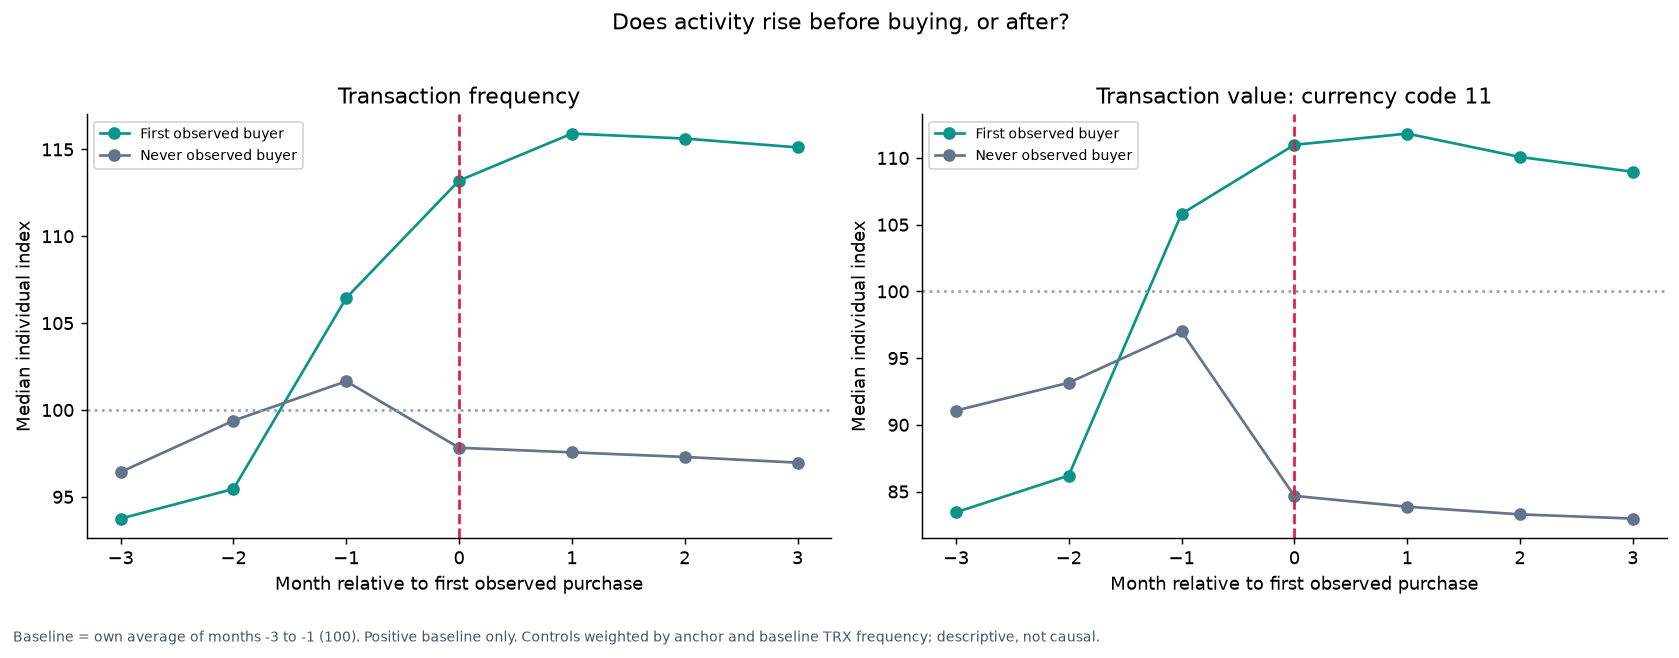

**outputs/purchase_event_financial_eda_20261118/02_value_change.png**

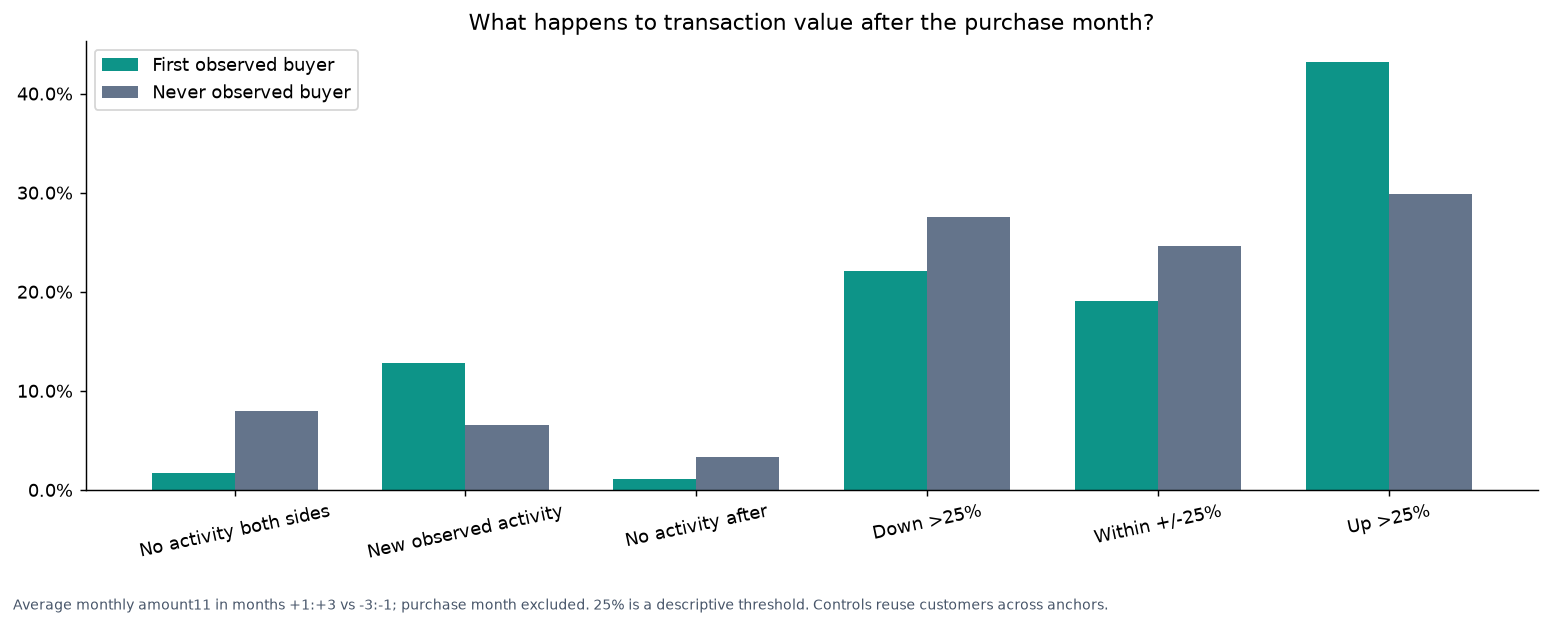

**outputs/purchase_event_financial_eda_20261118/03_engagement_timing.png**

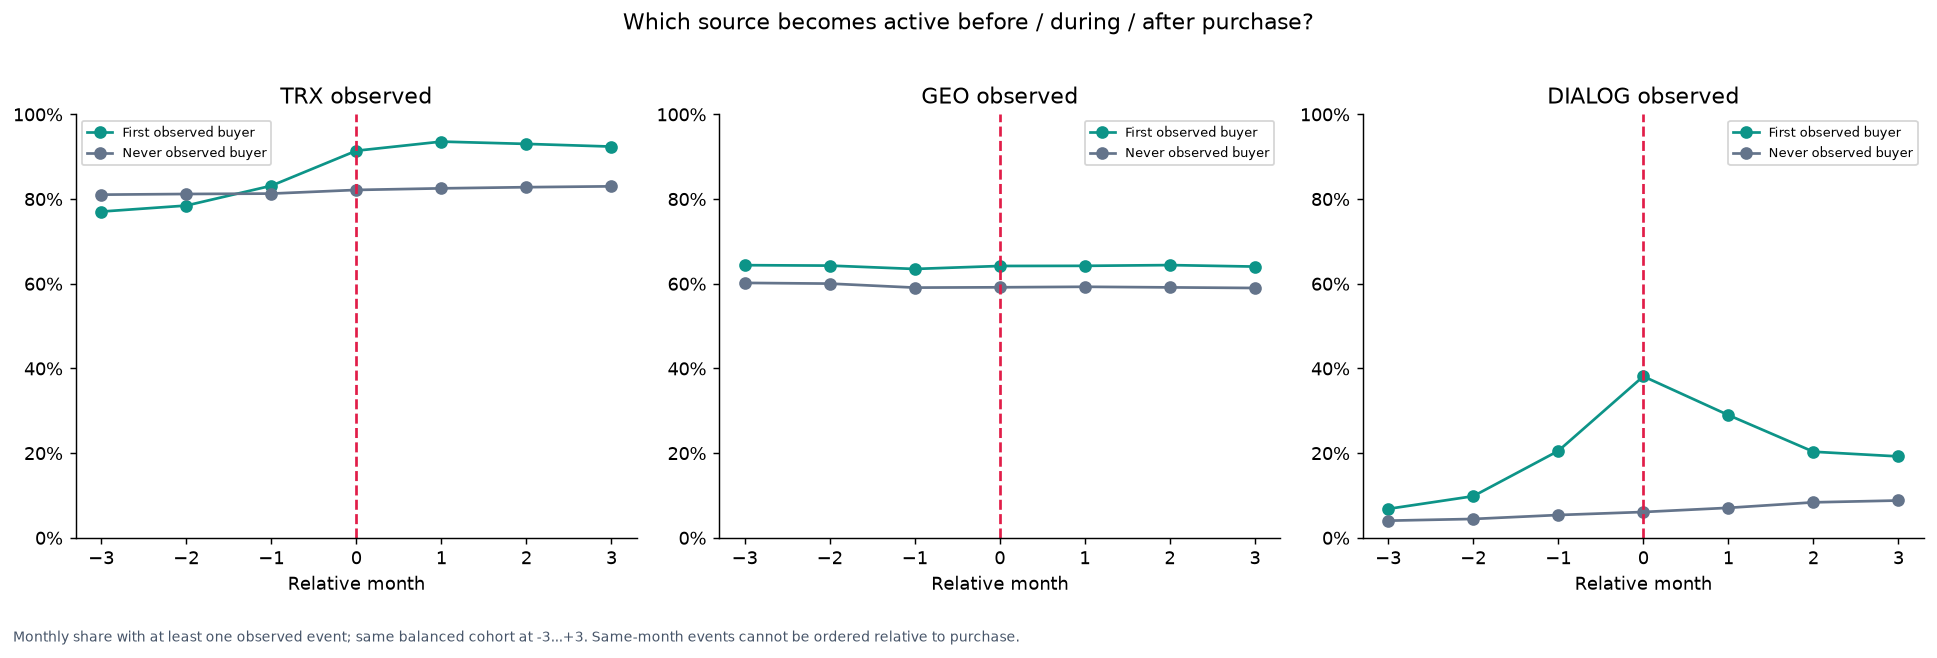

**outputs/purchase_event_financial_eda_20261118/04_financial_concentration.png**

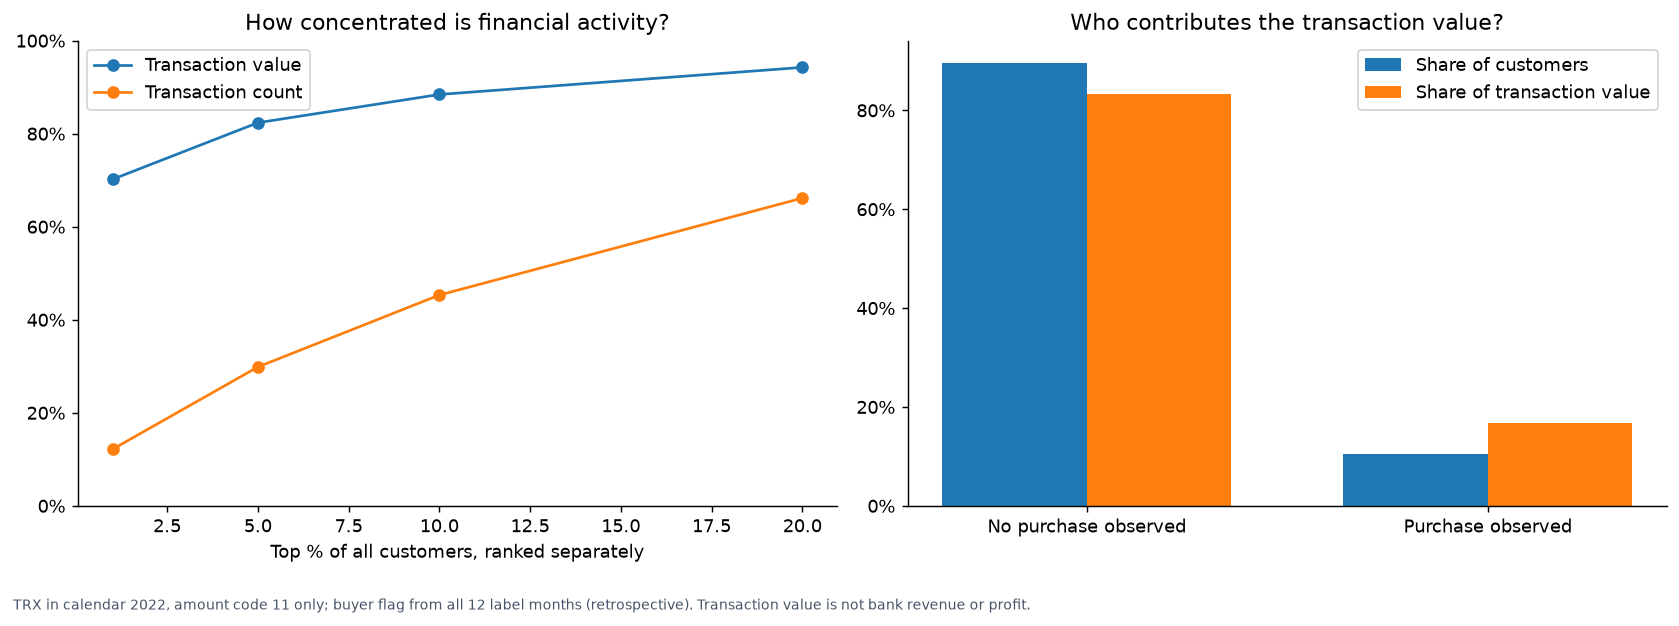

**outputs/purchase_event_financial_eda_20261118/05_transaction_mix_shift.png**

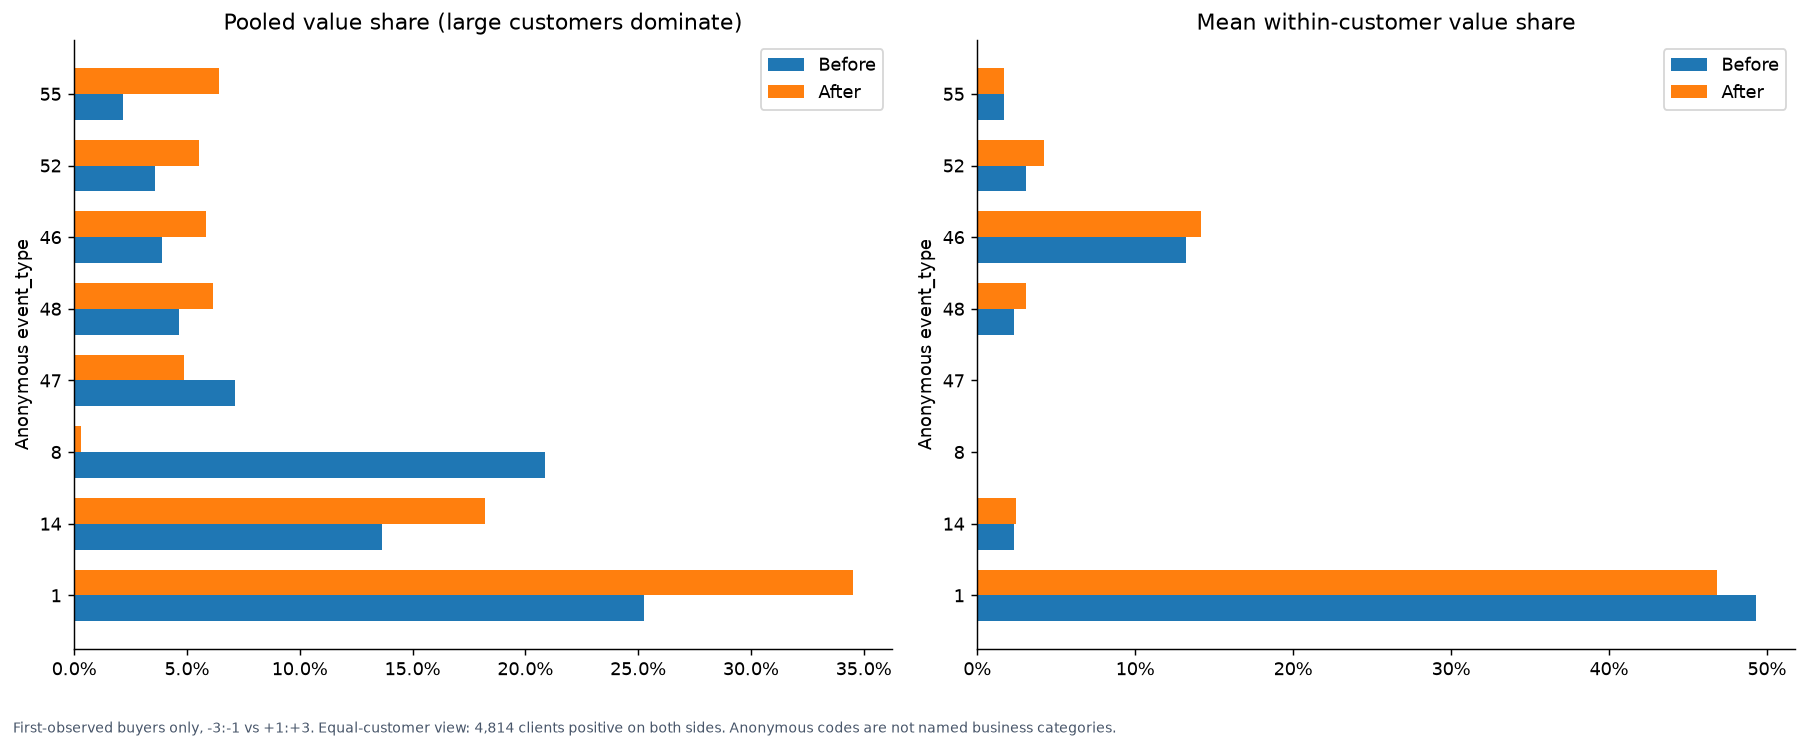

**outputs/purchase_event_financial_eda_20261118/06_observation_order.png**

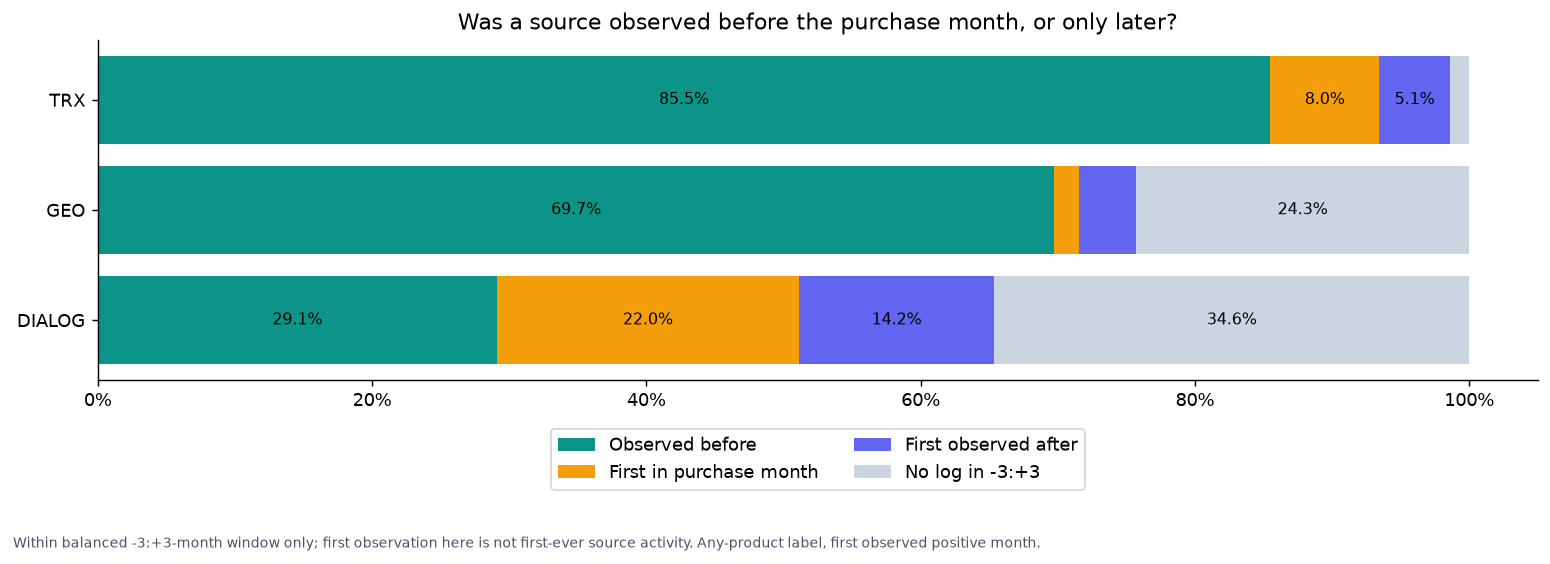

**outputs/purchase_event_financial_eda_20261118/07_headline_decline_bridge.png**

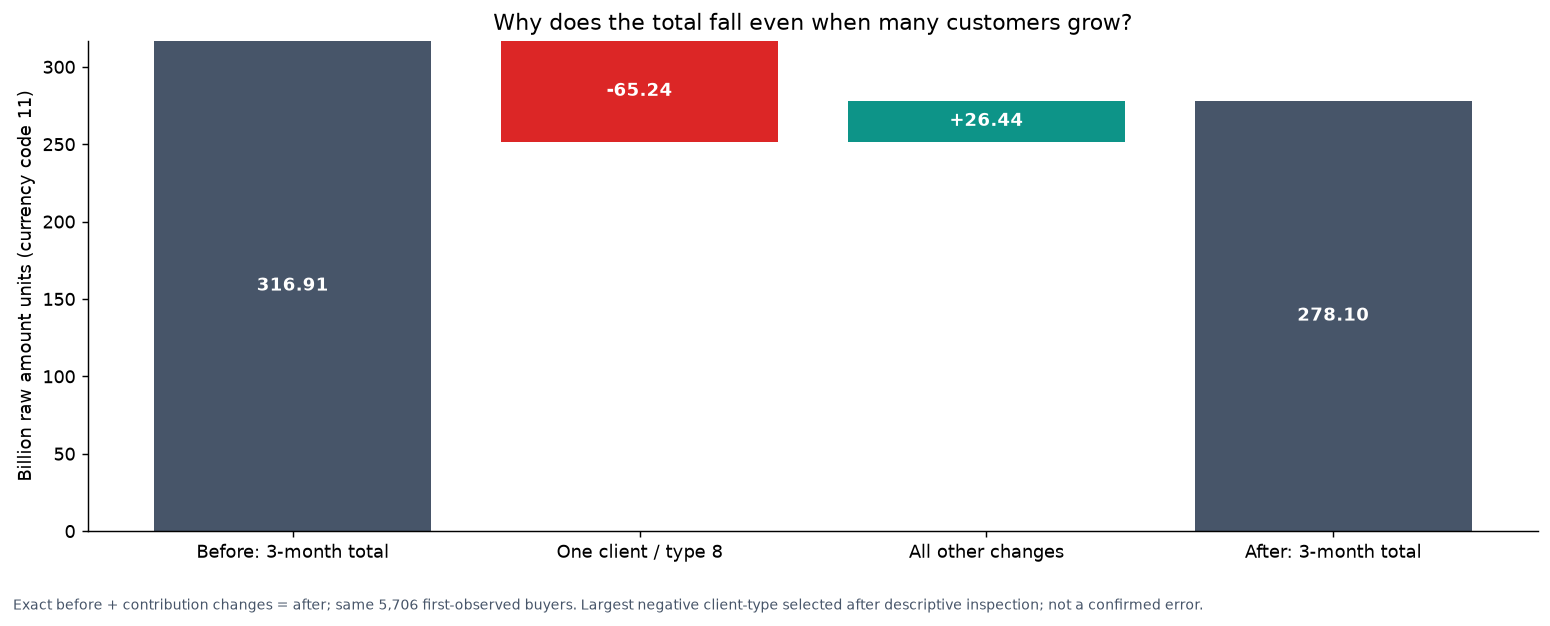

**outputs/purchase_event_financial_eda_20261118/activity_event_indices.csv** — 5 dòng đầu

,metric,group,relative_month,n,index
0,trx_events,First observed buyer,-3,4877,93.750000
1,trx_events,First observed buyer,-2,4877,95.454545
2,trx_events,First observed buyer,-1,4877,106.451613
3,trx_events,First observed buyer,0,4877,113.207547
4,trx_events,First observed buyer,1,4877,115.909091


**outputs/purchase_event_financial_eda_20261118/buyer_financial_contribution.csv** — 5 dòng đầu

,ever_buyer,customers,amount11,events,amount_share,customer_share
0,False,89813,1.240848e+13,15626252.0,0.832474,0.896123
1,True,10411,2.497071e+12,3753164.0,0.167526,0.103877


**outputs/purchase_event_financial_eda_20261118/buyer_timing_by_anchor.csv** — 5 dòng đầu

,anchor,relative_month,customers,trx_active,geo_active,dialog_active
0,2022-04-01,-3,1497,0.839679,0.670007,0.110220
1,2022-04-01,-2,1497,0.845691,0.672011,0.114228
2,2022-04-01,-1,1497,0.875752,0.624582,0.146293
3,2022-04-01,0,1497,0.935872,0.656647,0.232465
4,2022-04-01,1,1497,0.945224,0.663995,0.174349


... (15 outputs left out)

,group,band,share,n
0,First observed buyer,No activity both sides,0.017350,99
1,First observed buyer,New observed activity,0.127936,730
2,First observed buyer,No activity after,0.011041,63
3,First observed buyer,Down >25%,0.221171,1262
4,First observed buyer,Within +/-25%,0.190676,1088


**outputs/purchase_event_financial_eda_20261118/value_concentration.csv** — 5 dòng đầu

,metric,top_pct,n,share,buyer_share
0,trx_events,1,1003,0.121864,0.382851
1,trx_events,5,5012,0.298565,0.321229
2,trx_events,10,10023,0.453142,0.276265
3,trx_events,20,20045,0.661595,0.228236
4,trx_events,100,100224,1.000000,0.103877


File kết quả khác: `outputs/purchase_event_financial_eda_20261118/REPORT.md`, `outputs/purchase_event_financial_eda_20261118/customer_pre_post_changes.parquet`, `outputs/purchase_event_financial_eda_20261118/dialog_monthly.parquet`, `outputs/purchase_event_financial_eda_20261118/event_panel.parquet`, `outputs/purchase_event_financial_eda_20261118/findings.json`, `outputs/purchase_event_financial_eda_20261118/geo_monthly.parquet`, `outputs/purchase_event_financial_eda_20261118/headline_change_bridge.json`, `outputs/purchase_event_financial_eda_20261118/labels_any.parquet`, `outputs/purchase_event_financial_eda_20261118/manifest.json`, `outputs/purchase_event_financial_eda_20261118/monthly_panel.parquet`, `outputs/purchase_event_financial_eda_20261118/trx_monthly.parquet`, `outputs/purchase_event_financial_eda_20261118/trx_type_monthly.parquet`, `outputs/purchase_event_financial_eda_20261118/validation.json`

In [9]:
show_generated_results(__eda_started_ns, 'src/scripts/analyze_purchase_event_financial_eda.py')